In [290]:
import pandas as pd
from astropy.io import fits
import numpy as np
from astropy.table import Table
import matplotlib.pyplot as plt
import subprocess
import os
from math import sin, cos, tan, radians, sqrt, pi
from os.path import join
from matplotlib.pylab import *

In [291]:
# Initialisation and parameters
# Defines inputs
# Run fearlessly

cat_csv = pd.read_csv("/Users/kyriakos.trakakis/Downloads/Other_Stuff/ATLASGAL_CSC_distances.csv")  # Example CSV

cat_csv = cat_csv[
    (cat_csv['gal_long_peak'] >= 17) & 
    (cat_csv['gal_long_peak'] <= 47)
].reset_index(drop=True)

dataset      = "FGN"
region       = "037_047"
isotopologue = "13CO"
SNR_lim      = 0
v_lim        = 3
minor_lim    = 69

if dataset == "CHIMPS" or dataset == "COHRS":
    if isotopologue == "12CO":
        dataset = "COHRS"
    elif isotopologue == "13CO":
        dataset = "CHIMPS"


mult_path = f"/Users/kyriakos.trakakis/Downloads/CHIMPS_COHRS/{isotopologue}/"

cat_csv['vlsr'] = pd.to_numeric(cat_csv['V_lsr'], errors='coerce')
cat_csv = cat_csv.dropna(subset=['gal_long_peak', 'gal_lat_peak', 'vlsr']).reset_index(drop=True)

base_prefix     = f"FGN_{region}_13CO_23arcsec_aligned_SNR_min_del_2_parallel_cluster"
input_filename  = base_prefix + "s.fits"
mult_file       = mult_path +f"{dataset}_{region}_{isotopologue}_23arcsec_aligned"
mult_filename   = mult_file + '.fits'
mult_sdf        = mult_file + '.sdf'
#SNR_filename    = mult_path + f"{dataset}_{region}_{isotopologue}_23arcsec_aligned_SNR.fits"
SNR_filename    = mult_path.replace("13CO","12CO") + f"COHRS_{region}_12CO_23arcsec_aligned_SNR.fits"
COLTE_N13_file  = f"/Users/kyriakos.trakakis/COLTE/colte_{dataset}_{region}_23arcsec_aligned_N13CO.fits"

clusters_path     = '/Users/kyriakos.trakakis/Downloads/CHIMPS_COHRS/13CO/'
clusters_file     = f"FGN_{region}_23arcsec_aligned_SNR_min_del_2_parallel_clusters_table.fits"
csv_output        = mult_path +f"{dataset}_{isotopologue}_{region}_vrms_3_X_factor_masses_SNR{SNR_lim}.csv"
table             = Table.read(clusters_path + clusters_file, format='fits')

df = table.to_pandas()
df = df[(df["minor_arcsec"] > minor_lim / 2.354) & (df["sigv_kms"] > v_lim / 2.354)]
df = df.drop(['luminosity', 'volume', 'flux'], axis = 1)



l_atlasgal = cat_csv['gal_long_peak']
b_atlasgal = cat_csv['gal_lat_peak']
v_atlasgal = cat_csv['vlsr']
d_atlasgal = cat_csv['distance']


# FITS (GRS) example
l_fgn = df['x_cen']
b_fgn = df['y_cen']
v_fgn = df['v_cen'] / 1000
angle = df['position_angle']

dl = np.maximum(df['major_arcsec'] / 3600 * abs(np.cos(angle*np.pi/180)), df['minor_arcsec'] * abs(np.sin(angle*np.pi/180)) / 3600) / 2 * 2.354
db = np.maximum(df['major_arcsec'] / 3600 * abs(np.sin(angle*np.pi/180)), df['minor_arcsec'] * abs(np.cos(angle*np.pi/180)) / 3600) / 2 * 2.354
dv = df['sigv_kms'] / 2 * 2.354  # Or define your own constant window like ±1 km/s

In [292]:
# Runs section 1, Atlasgal matcher rectangles
# Saves an output

# --- Match sources ---
matches = []

for i in range(len(df)):
    for j in range(len(cat_csv)):
        if (abs(l_atlasgal.iloc[j] - l_fgn.iloc[i]) <= dl.iloc[i] and
            abs(b_atlasgal.iloc[j] - b_fgn.iloc[i]) <= db.iloc[i] and
            abs(v_atlasgal.iloc[j] - v_fgn.iloc[i]) <= dv.iloc[i]):
            matches.append({
                'fgn_index': df['_idx'].iloc[i],
                'atlasgal_name': cat_csv['atlas_name'].iloc[j],  # or gname_jps
                'l_atlasgal': l_atlasgal.iloc[j],
                'b_atlasgal': b_atlasgal.iloc[j],
                'v_atlasgal': v_atlasgal.iloc[j],
                'l_fgn': round(l_fgn.iloc[i],2),
                'b_fgn': round(b_fgn.iloc[i],2),
                'v_fgn': round(v_fgn.iloc[i],2),
                'l_distance': round((l_atlasgal.iloc[j] - l_fgn.iloc[i]) / dl.iloc[i],2),
                'b_distance': round((b_atlasgal.iloc[j] - b_fgn.iloc[i]) / db.iloc[i],2),
                'v_distance': round((v_atlasgal.iloc[j] - v_fgn.iloc[i]) / dv.iloc[i],2),
                'distance': d_atlasgal.iloc[j]
            })

# Now extract all matched _idx values
matched_ids = {match['fgn_index'] for match in matches}

# Add a 'has_match' column to df
df['has_match'] = df['_idx'].isin(matched_ids)

df_matches = pd.DataFrame(matches)
print(df_matches)
#df_matches.to_csv("FGN_37_47_matched_sources_test.csv", index=False)

if df_matches.empty:
    most_common_distances = pd.DataFrame(columns=['fgn_index','most_common_distance'])
else:
    most_common_distances = (
        df_matches.groupby('fgn_index')['distance']
        .agg(lambda x: x.mode().iloc[0] if not x.mode().empty else None)
        .reset_index()
        .rename(columns={'distance': 'most_common_distance'})
    )

#most_common_distances = (
#    df_matches.groupby('fgn_index')['distance']
#    .agg(lambda x: x.mode().iloc[0] if not x.mode().empty else None)
#    .reset_index()
#    .rename(columns={'distance': 'most_common_distance'})
#)

print(most_common_distances)

# Merge most_common_distance into the main DataFrame on 'fgn_index' and '_idx'
df = df.merge(most_common_distances, how='left', left_on='_idx', right_on='fgn_index')

# Fill NaN (i.e., unmatched sources) with 0
df['AGAL_distance'] = df['most_common_distance'].fillna(0)

# Optionally drop the 'fgn_index' and 'most_common_distance' columns if not needed
df = df.drop(columns=['fgn_index', 'most_common_distance'])

    fgn_index       atlasgal_name  l_atlasgal  b_atlasgal  v_atlasgal  l_fgn  \
0         290  AGAL037.554+00.201      37.554       0.201        85.1  37.53   
1         290  AGAL037.671+00.142      37.671       0.142        87.8  37.53   
2         425  AGAL038.162-00.076      38.162      -0.076        83.3  38.59   
3         425  AGAL038.202-00.067      38.202      -0.067        83.4  38.59   
4         425  AGAL038.371-00.149      38.371      -0.149        81.4  38.59   
..        ...                 ...         ...         ...         ...    ...   
88      11428  AGAL043.183-00.044      43.183      -0.044        11.2  43.18   
89      11428  AGAL043.226-00.039      43.226      -0.039         6.2  43.18   
90      11428  AGAL043.236-00.047      43.236      -0.047         8.2  43.18   
91      12091  AGAL045.623-00.042      45.623      -0.042         7.9  45.61   
92      12091  AGAL045.641-00.016      45.641      -0.016         7.2  45.61   

    b_fgn  v_fgn  l_distance  b_distanc

In [293]:
# Convert to Pandas DataFrame and add distance inputs
# Run fearlessly


cluster_ids = df['_idx']
cluster_ids = cluster_ids.to_numpy()

df_inp = pd.DataFrame({
    'Source'       : df['_idx'],
    'Long (deg)'   : df['x_cen'],
    'Lat (deg)'    : df['y_cen'],
    'vlsr (km/s)'  : df['v_cen']/1000,
    'v_rms (km/s)' : df['v_rms']/1000,
    'P': 0.5
})

In [294]:
# Creates the sources.info file in v2.4.1
# Saves necessary file

# Save to .inp file with space-separated columns
output_path = '/Users/kyriakos.trakakis/Downloads/v2.4.1_bundle/'
output_file = 'sources_info.inp'

with open(output_path+output_file, 'w') as f:
    f.write('! Source Long(deg) Lat(deg) vlsr(km/s) v_rms(km/s) P\n')  # comment line
    df_inp.to_csv(f, sep=' ', index=False, header=False, float_format='%.4f')


# Path to the Fortran executable
exe_path = "/Users/kyriakos.trakakis/Downloads/v2.4.1_bundle/distance_calculator"
distance_dir='/Users/kyriakos.trakakis/Downloads/v2.4.1_bundle/'
os.chdir(distance_dir)

try:
    result = subprocess.run([exe_path], check=True, capture_output=True, text=True)
    print("Program output:")
    print(result.stdout)
except subprocess.CalledProcessError as e:
    print("Error running Fortran program:")
    print(e.stderr)

Program output:
 Bayesian distance estimator: 2019: September 24, 2019

 Reading in file "probability_controls.inp                        "
 Max Prob_SA = 0.85
 Max Prob_KD = 0.85
 Max Prob_GL = 0.85
 Max Prob_PS = 0.15
 Max Prob_PM = 0.85


 Openning input ascii file "galaxy_data_Univ.inp            "
 Comment lines follow:
 ! Galactic and Solar Motion parameters                                          
 ! for use with 2-parameter Persic "Universal" rotation curve                    
 End of Comment lines

 Galaxy model:
  Ro, a1, a2, a3:                         8.15   236.000     0.960     1.620
  Solar Motion (Uo,Vo,Wo):               10.60     10.70      7.60
  Source Peculiar Motion (Us,Vs,Ws):      0.00      0.00      0.00

 Getting Spiral arm segment data:
 

  Read file Out_lbvRBD.2019      containing 176 (l,b,v,R,beta,D) values.
       Spanning longitude range:    0.0 to  252.0 deg.

  Read file Per_lbvRBD.2019      containing 272 (l,b,v,R,beta,D) values.
       Spanning long

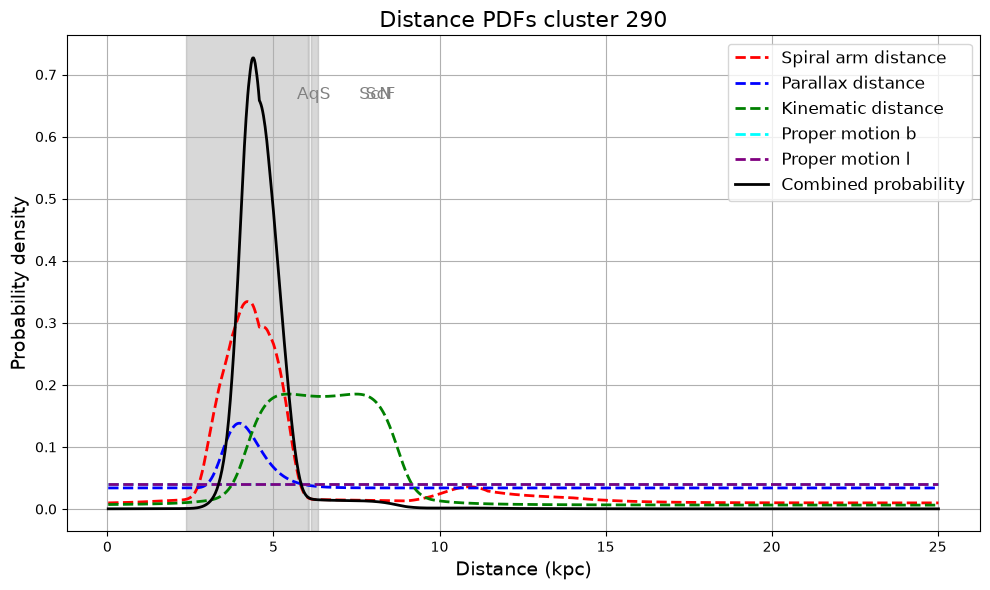

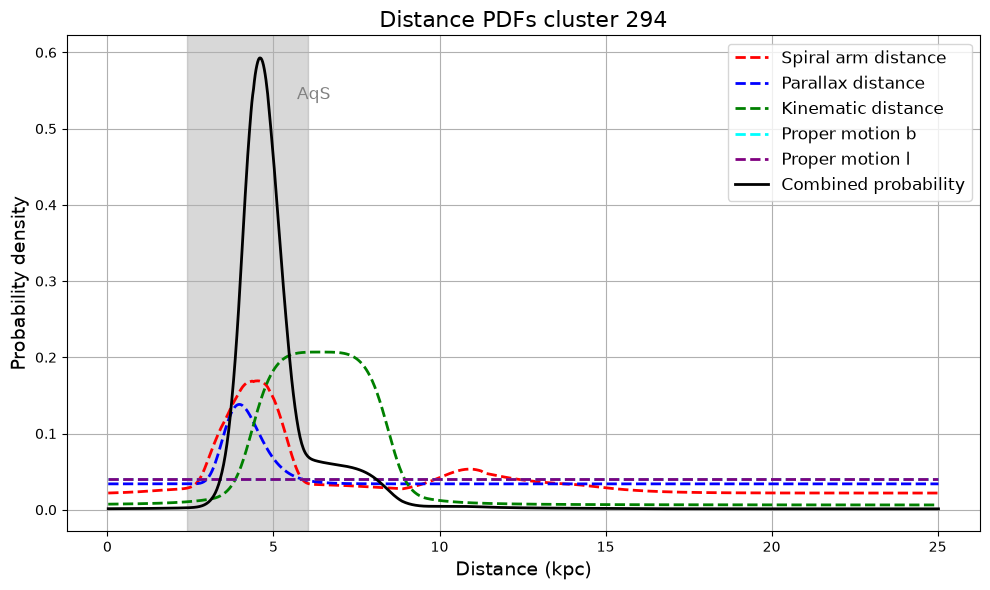

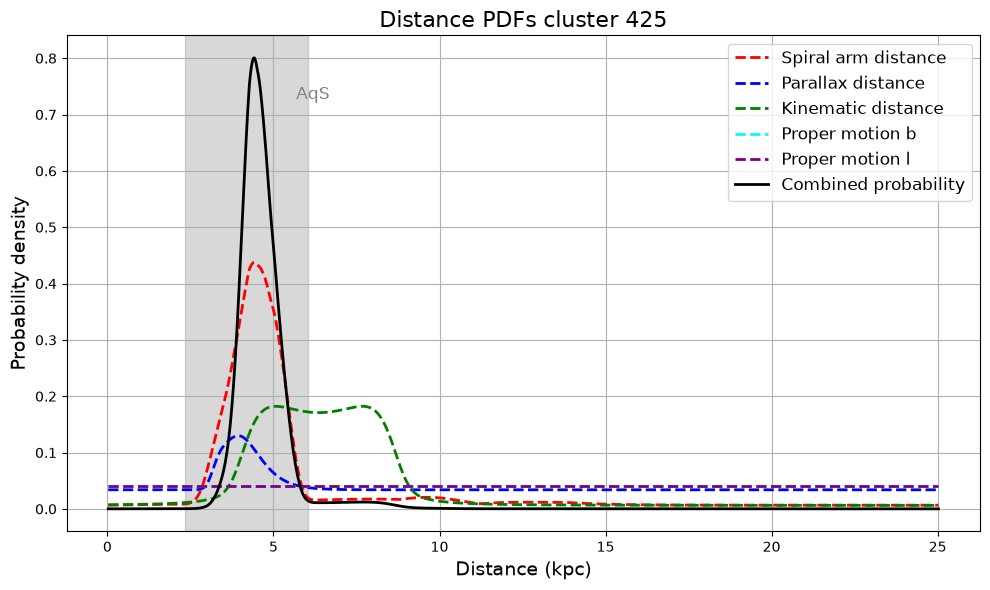

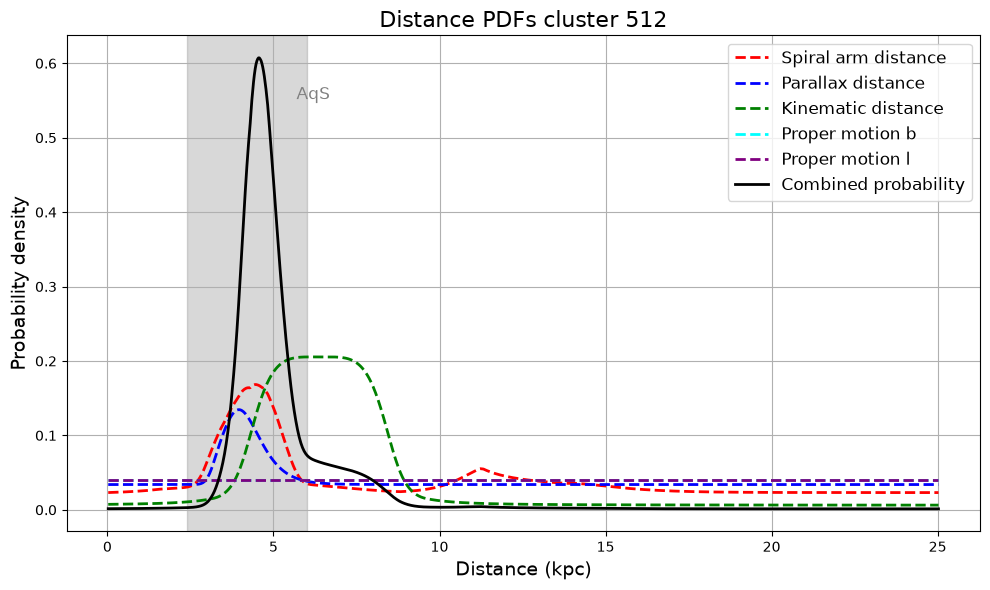

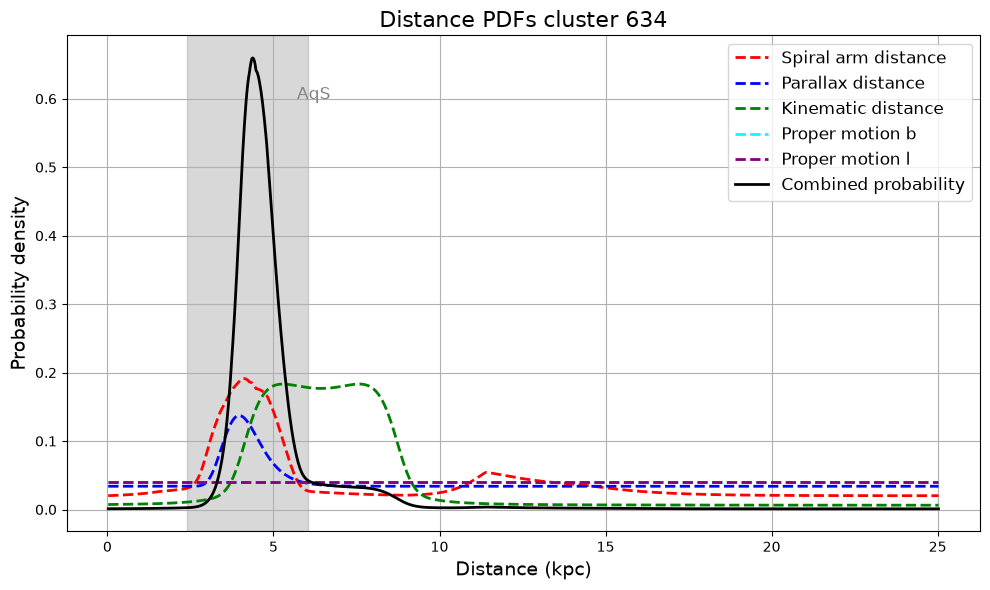

...

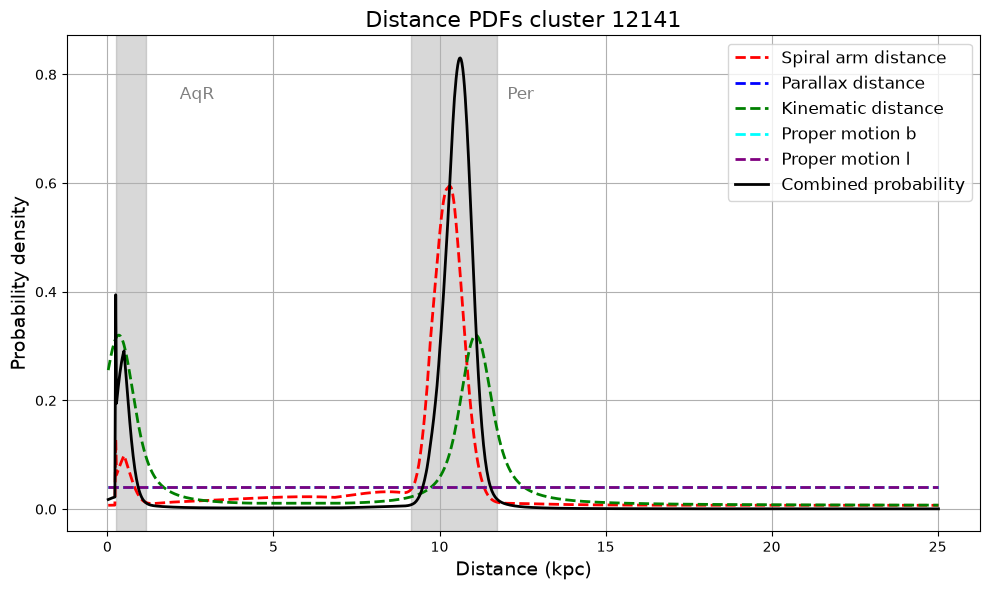

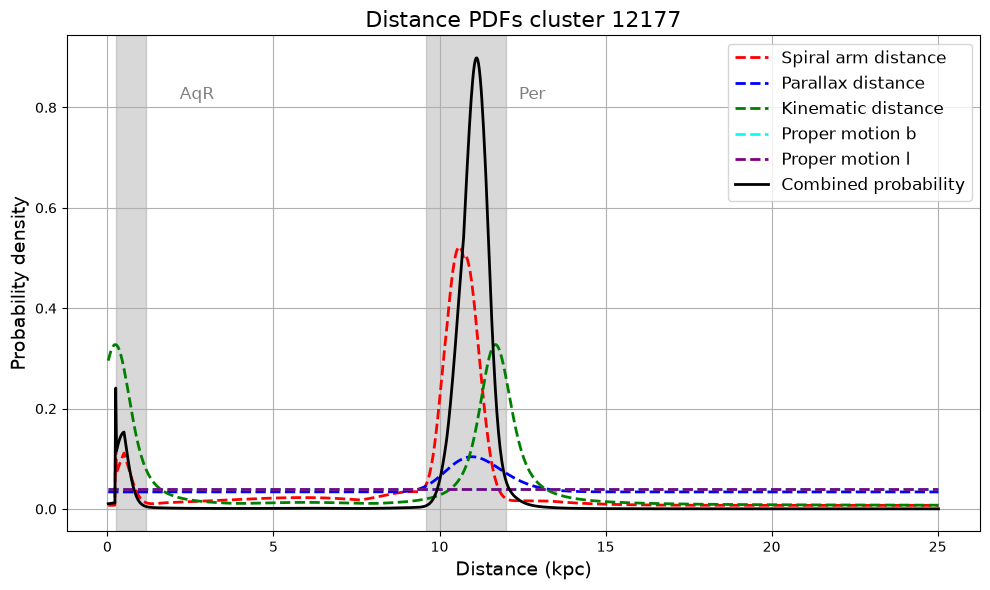

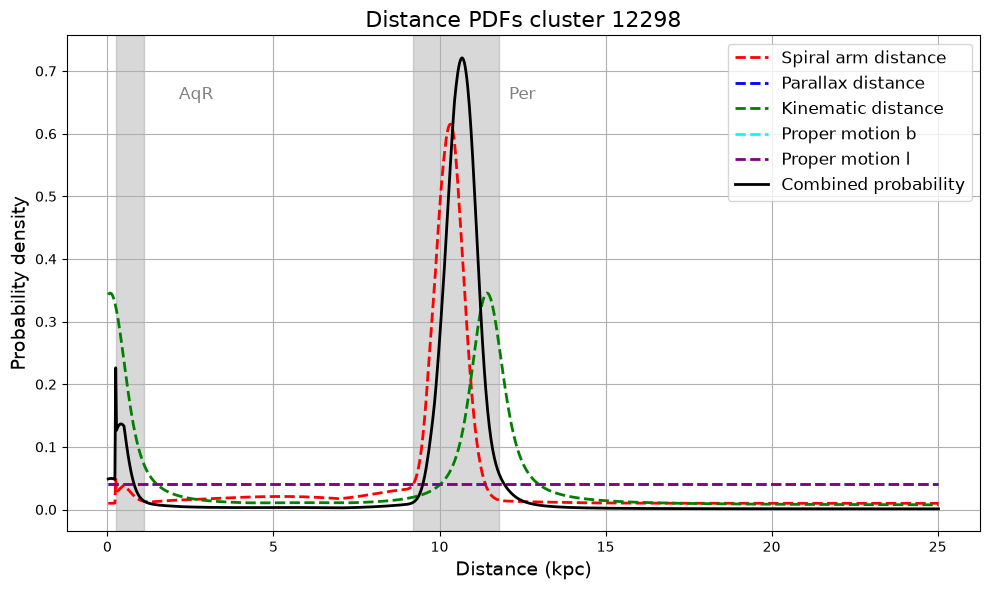

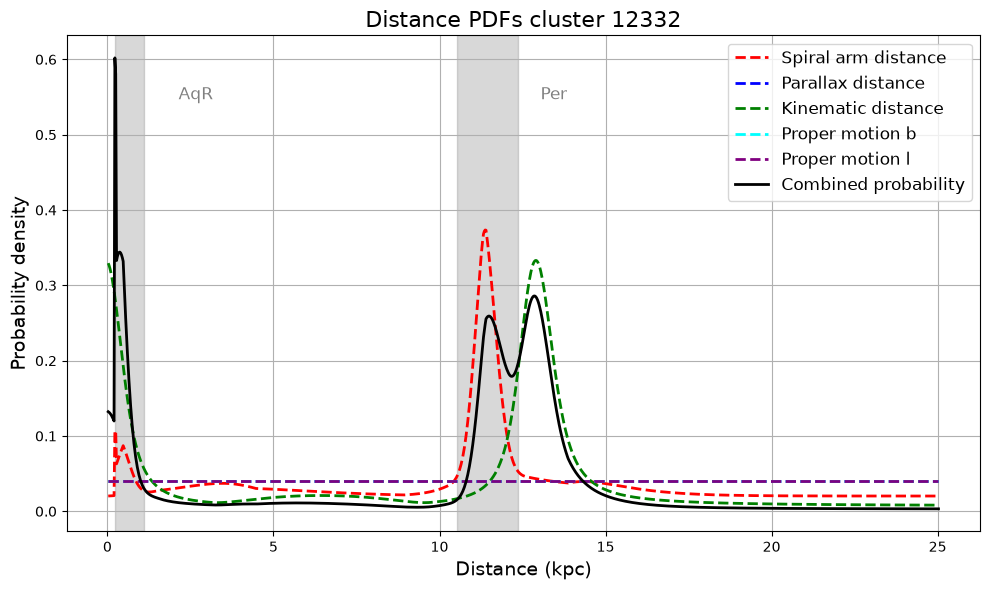

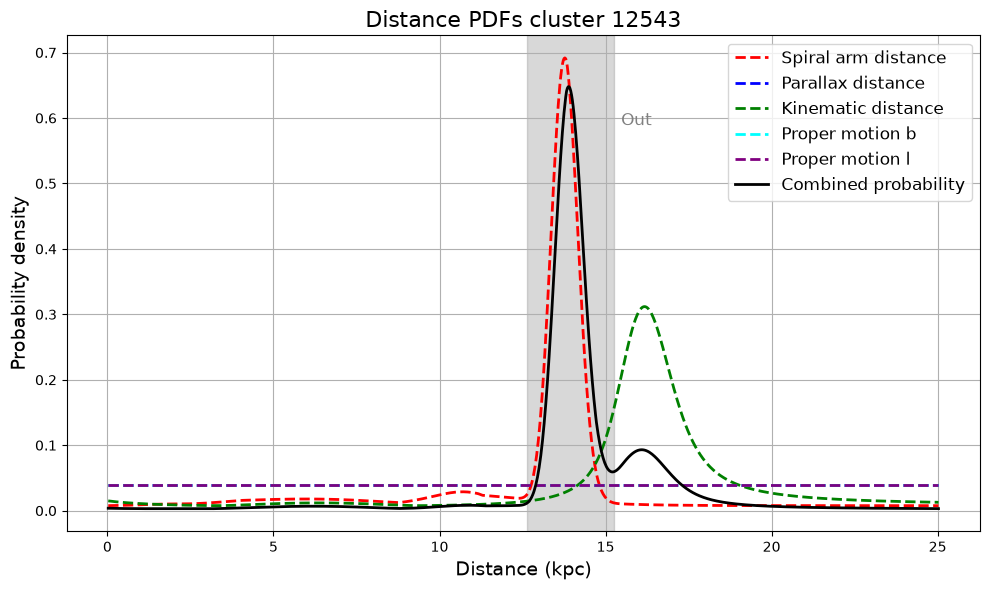

In [295]:
# Plots the distances
# Run fearlessly and optionally

def plot_distance_pdf(cluster_number,distance_dir):

    data_final     = np.loadtxt(distance_dir + f'{cluster_number}_final_distance_pdf.dat', skiprows=2)  # Skip header: "D(kpc) Probability"
    distances1     = data_final[:, 0]   # Column 1: D(kpc)
    probabilities1 = data_final[:, 1]  # Column 2: Probability

    data_spiral    = np.loadtxt(distance_dir + str(cluster_number)+'_arm_latitude_pdf.dat', skiprows=2, usecols=(0, 1))
    distances2     = data_spiral[:, 0]
    probabilities2 = data_spiral[:, 1]

    data_parallax  = np.loadtxt(distance_dir + str(cluster_number)+'_parallaxes_pdf.dat', skiprows=2)
    distances3     = data_parallax[:, 0]
    probabilities3 = data_parallax[:, 1]

    data_kinematic = np.loadtxt(distance_dir + str(cluster_number)+'_kinematic_distance_pdf.dat', skiprows=2)
    distances4     = data_kinematic[:, 0]
    probabilities4 = data_kinematic[:, 1]

    data_latitude  = np.loadtxt(distance_dir + str(cluster_number)+'_pm_bee_distance_pdf.dat', skiprows=2)
    distances5     = data_latitude[:, 0]
    probabilities5 = data_latitude[:, 1]

    data_longitude = np.loadtxt(distance_dir + str(cluster_number)+'_pm_ell_distance_pdf.dat', skiprows=2)
    distances6     = data_longitude[:, 0]
    probabilities6 = data_longitude[:, 1]
    
    arm_ranges = []
    arm_file = distance_dir + str(cluster_number) + '_arm_ranges.dat'
    with open(arm_file, 'r') as f:
        for line in f:
            if line.strip().startswith('!') or not line.strip():
                continue
            parts = line.split()
            start, end, name = float(parts[0]), float(parts[1]), parts[2]
            if start > 0 and end > 0:
                arm_ranges.append((start, end, name))

# Plotting
    plt.figure(figsize=(10, 6))
    
    ymax = max(probabilities1)  # Adjust if you'd rather base it on other curves or overall max

    for start, end, name in arm_ranges:
    # Shading (transparent and no legend entry)
        plt.axvspan(start, end, color='gray', alpha=0.3, zorder=0)

    # Label the spiral arm at the midpoint
        midpoint = (start + end) / 2
        plt.text(midpoint+2, ymax * 0.9, name, fontsize=12, ha='center', va='bottom', color='gray')
    
    plt.plot(distances2, probabilities2, label='Spiral arm distance', color='red', lw=2, linestyle='--')
    plt.plot(distances3, probabilities3, label='Parallax distance', color='blue', lw=2, linestyle='--')
    plt.plot(distances4, probabilities4, label='Kinematic distance', color='green', lw=2, linestyle='--')
    plt.plot(distances5, probabilities5, label='Proper motion b', color='cyan', lw=2, linestyle='--')
    plt.plot(distances6, probabilities6, label='Proper motion l', color='purple', lw=2, linestyle='--')
    plt.plot(distances1, probabilities1, label='Combined probability', color='black', lw=2)

    plt.xlabel('Distance (kpc)', fontsize=14)
    plt.ylabel('Probability density', fontsize=14)
    plt.title(f'Distance PDFs cluster {cluster_number}', fontsize=16)
    plt.legend(fontsize=12)
    plt.grid(True)
    plt.tight_layout()
    plt.show()

for id in cluster_ids:
    plot_distance_pdf(id, distance_dir)

In [296]:
# Initialisess stuff
# Run fearlessly

os.chdir(clusters_path)

# Constants
a1, a2, a3 = 1.0077, 0.0394, 0.0071  # Brand & Blitz (1993)
theta0     = 236.0              # km/s
R0         = 8.15               # kpc
omega0     = theta0 / R0
dtor       = pi / 180

# Initialize outputs
n              = len(df)
R              = np.zeros(n)
Vcalc          = np.zeros(n)
d_near         = np.zeros(n)
d_far          = np.zeros(n)
distance       = np.full(n, np.nan)
dist_method    = np.zeros(n, dtype=int)

In [297]:
# Full rotation curve code
# Run fearlessly

# Step 1: Rotation Curve + Near/Far Distance Calculation
for i in range(n):
    l, b, V = df['x_cen'][i], df['y_cen'][i], df['v_cen'][i]/1000
    
    Ri = 0.5
    while True:
        Ri += 0.01
        wi = omega0 * ((a1 * (Ri/R0)**(a2 - 1)) + a3 * (R0 / Ri))
        Vtest = R0 * (wi - omega0) * sin(radians(l)) * cos(radians(b))
        if abs(Vtest - V) < 0.4:
            break
    
    R[i] = Ri
    Vcalc[i] = Vtest

    A = cos(radians(b))**2
    B = 2 * R0 * cos(radians(b)) * cos(radians(l))
    C = R0**2 - Ri**2
    delta = B**2 - 4 * A * C

    if delta <= 0:
        d1 = d2 = R0 * cos(radians(l)) / cos(radians(b))
    else:
        sqrt_delta = sqrt(delta)
        d1 = -( -B + sqrt_delta ) / (2 * A)
        d2 = -( -B - sqrt_delta ) / (2 * A)

    d_near[i], d_far[i] = min(d1, d2), max(d1, d2)

    # Outer Galaxy check
    if R[i] >= R0 or d_near[i] <= 0:
        distance[i] = d_far[i]
        dist_method[i] = 2  # Outer Galaxy

# Step 2: Tangent Point Method
# Apply only to unresolved sources (dist_method = 0)
for i in range(n):
    if dist_method[i] != 0:
        continue
    l = df['x_cen'][i]
    V = df['v_cen'][i]
    tan_vel = theta0 * sin(radians(l))
    if abs(V - tan_vel) < 10 and (d_far[i] - d_near[i]) <= 1.0:
        distance[i] = (d_near[i] + d_far[i]) / 2
        dist_method[i] = 3  # Tangent method

# Step 3: Scale Height Method
# Still unresolved sources
for i in range(n):
    if dist_method[i] != 0:
        continue
    b = df['y_cen'][i]
    z = d_far[i] * 1000 * tan(radians(b))  # pc
    if abs(z) > 120:
        distance[i] = d_near[i]
        dist_method[i] = 4  # Scale height method

# Step 4: Append Results
df['R_GC'] = R
df['d_near'] = d_near
df['d_far'] = d_far
df['distance'] = distance
df['dist_method'] = dist_method

In [298]:
# Function definition
# Run fearlessly

def determine_distance_assignment(txt_path, d_near, d_far):
    components = []

    with open(txt_path, 'r') as f:
        lines = f.readlines()

    # Filter lines that contain "Probability component"
    prob_lines = [line.strip() for line in lines if line.strip().startswith("Probability component")]

    for line in prob_lines:
        parts = line.split()
        try:
            dist = float(parts[3])
            prob = float(parts[5])
            components.append((dist, prob))
        except (IndexError, ValueError):
            continue

    if not components:
        raise ValueError("No valid probability components found.")

    # Get distance of component with highest probability
    best_dist, _ = max(components, key=lambda x: x[1])
    
    all_distances = [comp[0] for comp in components]
    min_distance = min(all_distances)
    max_distance = max(all_distances)

    if abs(best_dist - d_near) <= abs(best_dist - d_far):
            return 'near'
    else:
            return 'far'

prt_dir = '/Users/kyriakos.trakakis/Downloads/v2.4.1_bundle/'  # Update if needed
final_distances = []
distance_flags = []  # Optional: stores 'near' or 'far'

In [299]:
# Selects near or far distances
# Run fearlessly

for idx, row in df.iterrows():
    obj_id = int(row['_idx'])
    prt_file = os.path.join(prt_dir, f"{obj_id}.prt")

    try:
        choice = determine_distance_assignment(prt_file, row['d_near'], row['d_far'])
        if choice == 'near':
            final_distances.append(row['d_near'])
            distance_flags.append('near')
        else:
            final_distances.append(row['d_far'])
            distance_flags.append('far')
    except Exception as e:
        print(f"Warning: Failed to process {prt_file} due to {e}")
        final_distances.append(np.nan)
        distance_flags.append('error')

df['distance'] = final_distances
df['distance_flag'] = distance_flags  # Optional for debugging
#df['structure_type'] = df['structure_type'].str.decode('utf-8').str.strip() 

In [300]:
final_distance = []
for i in range(len(df)):
    if df['has_match'][i] and df['AGAL_distance'][i] != '---':
        final_distance.append(float(df['AGAL_distance'][i]))
    else:
        final_distance.append(df['distance'][i])

df['final_distance'] = final_distance

In [301]:
# Initialise stuff
# Run fearlessly

# --- Get the numbers of the clusters we work with ---
cluster_numbers = df['_idx']


# --- Load original data ---
with fits.open(os.path.join(clusters_path, input_filename)) as hdul:
    data = hdul[0].data
    header = hdul[0].header

with fits.open(mult_filename) as hdul:
    raw_data = hdul[0].data

# --- Grab the SNR mask ---
try:
    if os.path.exists(SNR_filename):
        with fits.open(SNR_filename) as hdul_SNR:
            data_SNR = hdul_SNR[0].data
            header_SNR = hdul_SNR[0].header
        mask_SNR = (data_SNR > SNR_lim)
    else:
        raise FileNotFoundError
except FileNotFoundError:
    print(f"Warning: {SNR_filename} not found. Using all-True mask.")
    # Create a dummy all-True mask of compatible shape
    # You must already have a known shape, e.g., from another array

#mask_SNR = np.ones_like(data, dtype=bool)

# --- Load COLTE densities ---
try:
    if os.path.exists(COLTE_N13_file):
        with fits.open(COLTE_N13_file) as hdul_COLTE_N13:
            data_COLTE_N13 = hdul_COLTE_N13[0].data
            header_COLTE_N13 = hdul_COLTE_N13[0].header
        has_COLTE = True
    else:
        raise FileNotFoundError
except FileNotFoundError:
    print(f"Warning: {COLTE_N13_file} not found. Using all-True mask.")
    # Create a dummy all-True mask of compatible shape
    # You must already have a known shape, e.g., from another array
    colte_masked = np.ones_like(data, dtype=bool)

has_COLTE = False

In [302]:
nonzero_pixels = []
total_flux     = []
COLTE_Mass     = []

for num in cluster_numbers:
    mask = (data == num)# & (~np.isnan(data_COLTE_N13))
    new_data = np.where(mask, raw_data, 0)
    new_data = np.where(mask_SNR, new_data, 0)

    if has_COLTE:
        # Only calculate COLTE-based mass if we have the file
        colte_masked = np.where(mask, data_COLTE_N13, 0)
        colte_mass   = np.nansum(colte_masked) * np.abs(header_COLTE_N13['CDELT3'])
        if header_COLTE_N13['CUNIT3'] == 'm/s':
            colte_mass = colte_mass / 1000
    else:
        colte_mass = 0

    new_data_good = new_data[~np.isnan(new_data)]
    #new_data_good = new_data_good[new_data_good >= 0]
    pixels_nonzero = np.count_nonzero(new_data_good)
    integ_flux = np.sum(new_data_good) / 2

    print(num)
    COLTE_Mass.append(colte_mass)

    total_flux.append(integ_flux)
    nonzero_pixels.append(pixels_nonzero)
    print("cluster pixels sum:", new_data.sum()) 
    print("integrated flux:", integ_flux)
    print("number of pixels:", pixels_nonzero)
    print("colte total density:", colte_mass)

290
cluster pixels sum: 1.03316375e+06
integrated flux: 516581.88
number of pixels: 455017
colte total density: 0
294
cluster pixels sum: 18252.406
integrated flux: 9126.203
number of pixels: 15000
colte total density: 0
425
cluster pixels sum: 2.1600905e+06
integrated flux: 1.0800452e+06
number of pixels: 1304742
colte total density: 0
512
cluster pixels sum: 15236.795
integrated flux: 7618.3975
number of pixels: 12273
colte total density: 0
634
cluster pixels sum: 35270.453
integrated flux: 17635.227
number of pixels: 21998
colte total density: 0
668
cluster pixels sum: 34397.59
integrated flux: 17198.795
number of pixels: 17223
colte total density: 0
691
cluster pixels sum: 237384.64
integrated flux: 118692.32
number of pixels: 151862
colte total density: 0
800
cluster pixels sum: 133839.6
integrated flux: 66919.8
number of pixels: 48710
colte total density: 0
819
cluster pixels sum: 10905.861
integrated flux: 5452.9307
number of pixels: 6459
colte total density: 0
872
cluster pixel

In [303]:
df['total_flux']   = total_flux # actually integrated
df['pixel_number'] = nonzero_pixels 
df['COLTE_Density']   = COLTE_Mass
df

,_idx,area_ellipse,area_exact,major_sigma,minor_sigma,position_angle,radius,v_cen,v_rms,x_cen,...,R_GC,d_near,d_far,distance,dist_method,distance_flag,final_distance,total_flux,pixel_number,COLTE_Density
0,290,24315.807069,67039.0,110.816811,50.383125,-178.481608,74.721465,86908.922869,6.389916,37.534597,...,5.06,5.488521e+00,7.437173,5.488521,0,near,4.900000,5.165819e+05,455017,0
1,294,2016.572753,4324.0,23.588058,19.630157,-172.953672,21.518301,89640.321209,4.155556,38.201046,...,5.02,6.404658e+00,6.404658,6.404658,0,near,6.404658,9.126203e+03,15000,0
2,425,84013.486605,204355.0,236.446078,81.586623,-175.789298,138.891458,81939.821982,7.071597,38.585309,...,5.22,5.182571e+00,7.558841,5.182571,0,near,6.500000,1.080045e+06,1304742,0
3,512,1091.289881,3253.0,19.668014,12.740360,159.880723,15.829642,88485.875567,4.393142,38.449789,...,5.06,6.382766e+00,6.382766,6.382766,0,near,6.382766,7.618397e+03,12273,0
4,634,1467.347944,4568.0,22.591910,14.913591,-165.792369,18.355558,84981.580239,4.122984,37.885224,...,5.12,5.352280e+00,7.512617,5.352280,0,near,5.352280,1.763523e+04,21998,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
154,12141,567.253429,1208.0,15.347724,8.486629,-162.642490,11.412731,8330.096988,2.804845,45.444871,...,7.86,4.215271e-01,11.014475,11.014475,0,far,11.014475,1.611401e+03,2987,0
155,12177,254.995263,684.0,8.642020,6.775150,-169.320296,7.651861,6563.560679,2.799835,43.002422,...,7.92,3.185738e-01,11.602022,11.602022,0,far,11.602022,2.348667e+03,3578,0
156,12298,474.617002,1448.0,13.795119,7.899869,60.867831,10.439331,4315.068291,3.558471,45.050410,...,8.04,1.567846e-01,11.358928,11.358928,0,far,11.358928,2.769652e+03,5302,0
157,12332,8475.918332,12112.0,72.261278,26.932905,105.763377,44.115826,1887.388250,3.939025,37.945349,...,8.15,1.634296e-13,12.854327,12.854327,0,far,12.854327,3.885027e+04,51794,0


In [304]:
# Spreadsheet calculations
# Run fearlesly

df['distance_cm'] = df['final_distance'] * 3.086 * pow(10,21)
df['Mean_flux']   =df['total_flux'] / df['pixel_number'] # actually integrated, not mean

# Constants
if isotopologue == "13CO":
    if dataset == "CHIMPS" or dataset == "COHRS":
        X_factor = 4.3 * pow(10,21)
    elif dataset == "FGN":
        X_factor = 6.52 * pow(10,20)
elif isotopologue == "12CO":
    if dataset == "CHIMPS" or dataset == "COHRS":
        X_factor = 4 * pow(10,20)
    elif dataset == "FGN":
        X_factor = 2 * pow(10,20)
elif isotopologue == "C18O":
    X_factor       = 6.52 * pow(10,20) * 6.5
    
mH2            = 1.67 * 2.72 * pow(10,-24)
Msol           = 2 * pow(10,33)
pixel_area_arc = pow(1.66*3.6,2)
arc_2_sr       = pow(np.pi/180/3600,2)

df['density']=X_factor*df['Mean_flux']

# Ellipse masses
df['semi_major_deg']= df['major_arcsec'] / 7200  # Divide by 7200 to turn major to semi-major too
df['semi_minor_deg']= df['minor_arcsec'] / 7200
df['semi_major_cm'] = df['semi_major_deg'] * df['distance_cm'] * np.pi / 180 * 2.354
df['semi_minor_cm'] = df['semi_minor_deg'] * df['distance_cm'] * np.pi / 180 * 2.354
df['NH2_ellipse']   = df['density'] * np.pi * df['semi_major_cm'] * df['semi_minor_cm']
df['M_ellipse_g']   = df['NH2_ellipse'] * mH2


# Pixel area masses
df['angular_size_sr']       = df['pixel_number'] * pixel_area_arc * arc_2_sr
df['area_cm2_pixel_method'] = df['angular_size_sr'] * pow(df['distance_cm'],2)
df['NH2_pixel']             = df['area_cm2_pixel_method'] * df['density']
df['M_pixel_g']             = df['NH2_pixel'] * mH2

df['M_ellipse_Sol'] = df['M_ellipse_g'] / Msol   
df['M_pixel_Sol']   = df['M_pixel_g'] / Msol
df['M_COLTE_Sol_CO']   = df['COLTE_Density'] / Msol * pixel_area_arc * arc_2_sr * pow(df['distance_cm'],2) * mH2

In [305]:
# Formatting the df
# Run fearlessly

df['area_ellipse']   = df['area_ellipse'].round(1)  # Round to 1 decimal place
df['area_exact']     = df['area_exact'].round(1)
df['major_sigma']    = df['major_sigma'].round(1)
df['minor_sigma']    = df['minor_sigma'].round(1)
df['position_angle'] = df['position_angle'].round(1)
df['radius']         = df['radius'].round(1)
df['v_cen']          = df['v_cen'].round(2)
df['v_rms']          = df['v_rms'].round(2)
df['x_cen']          = df['x_cen'].round(3)
df['y_cen']          = df['y_cen'].round(3)
df['radius_arcsec']  = df['radius_arcsec'].round(1)
df['sigv_kms']       = df['sigv_kms'].round(2)
df['xcens']          = df['xcens'].round(3)
df['ycens']          = df['ycens'].round(3)
df['vcens']          = df['vcens'].round(3)
df['major_arcsec']   = df['major_arcsec'].round(1)
df['minor_arcsec']   = df['minor_arcsec'].round(1)
df['R_GC']           = df['R_GC'].round(2)
df['d_near']         = df['d_near'].round(2)
df['d_far']          = df['d_far'].round(2)
df['distance']       = df['distance'].round(2)
df['final_distance'] = df['final_distance'].round(2)


df['distance_cm']           = df['distance_cm'].apply(lambda x: f'{x:.2e}') # Write to format 1e7
df['Mean_flux']             = df['Mean_flux'].round(2)
df['density']               = df['density'].apply(lambda x: f'{x:.2e}')
df['semi_major_deg']        = df['semi_major_deg'].round(3)
df['semi_minor_deg']        = df['semi_minor_deg'].round(3)
df['semi_major_cm']         = df['semi_major_cm'].apply(lambda x: f'{x:.2e}')
df['semi_minor_cm']         = pd.to_numeric(df['semi_minor_cm']).apply(lambda x: f'{x:.2e}')
df['NH2_ellipse']           = df['NH2_ellipse'].apply(lambda x: f'{x:.2e}')
df['M_ellipse_g']           = df['M_ellipse_g'].apply(lambda x: f'{x:.2e}')
df['M_ellipse_Sol']         = df['M_ellipse_Sol'].apply(lambda x: f'{x:.2e}')
df['angular_size_sr']       = df['angular_size_sr'].apply(lambda x: f'{x:.2e}')
df['area_cm2_pixel_method'] = df['area_cm2_pixel_method'].apply(lambda x: f'{x:.2e}')
df['NH2_pixel']             = df['NH2_pixel'].apply(lambda x: f'{x:.2e}')
#df['M_COLTE_Sol_CO']        = df['M_COLTE_Sol_CO'].apply(lambda x: f'{x:.2e}')
#df['COLTE_Density']         = df['COLTE_Density'].apply(lambda x: f'{x:.2e}')
df['M_pixel_g']             = df['M_pixel_g'].apply(lambda x: f'{x:.2e}')
df['M_pixel_Sol']           = df['M_pixel_Sol'].apply(lambda x: f'{x:.2e}')

In [306]:
# Saves csv

csv_output        = mult_path +f"{dataset}_{isotopologue}_{region}_X-factor_masses_3-2_12_voxels.csv"
df.to_csv(csv_output, index= False)

In [310]:
id = 1460

print('near_d = ' , df['d_near'].values[df['_idx']==id])
print('far_d = ' , df['d_far'].values[df['_idx']==id])
print('distance = ' , df['final_distance'].values[df['_idx']==id])
print('v_width =',df['sigv_kms'].values[df['_idx']==id])
print('Mass = ',df['M_pixel_Sol'].values[df['_idx']==id])
print('Rgc = ',df['R_GC'].values[df['_idx']==id])

near_d =  []
far_d =  []
distance =  []
v_width = []
Mass =  <ArrowStringArray>
[]
Length: 0, dtype: str
Rgc =  []


In [309]:
df

,_idx,area_ellipse,area_exact,major_sigma,minor_sigma,position_angle,radius,v_cen,v_rms,x_cen,...,semi_minor_cm,NH2_ellipse,M_ellipse_g,angular_size_sr,area_cm2_pixel_method,NH2_pixel,M_pixel_g,M_ellipse_Sol,M_pixel_Sol,M_COLTE_Sol_CO
0,290,24315.8,67039.0,110.8,50.4,-178.5,74.7,86908.92,6.39,37.535,...,2.60e+19,3.45e+60,1.57e+37,3.82e-04,8.73e+40,6.46e+61,2.94e+38,7.84e+03,1.47e+05,0.0
1,294,2016.6,4324.0,23.6,19.6,-173.0,21.5,89640.32,4.16,38.201,...,1.32e+19,2.62e+59,1.19e+36,1.26e-05,4.92e+39,1.95e+60,8.86e+36,5.95e+02,4.43e+03,0.0
2,425,84013.5,204355.0,236.4,81.6,-175.8,138.9,81939.82,7.07,38.585,...,5.58e+19,1.53e+61,6.95e+37,1.10e-03,4.41e+41,2.38e+62,1.08e+39,3.48e+04,5.40e+05,0.0
3,512,1091.3,3253.0,19.7,12.7,159.9,15.8,88485.88,4.39,38.450,...,8.56e+18,1.44e+59,6.53e+35,1.03e-05,4.00e+39,1.62e+60,7.35e+36,3.26e+02,3.67e+03,0.0
4,634,1467.3,4568.0,22.6,14.9,-165.8,18.4,84981.58,4.12,37.885,...,8.40e+18,1.76e+59,7.97e+35,1.85e-05,5.04e+39,2.63e+60,1.20e+37,3.99e+02,5.98e+03,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
154,12141,567.3,1208.0,15.3,8.5,-162.6,11.4,8330.10,2.80,45.445,...,9.84e+18,1.93e+59,8.78e+35,2.51e-06,2.90e+39,1.02e+60,4.63e+36,4.39e+02,2.31e+03,0.0
155,12177,255.0,684.0,8.6,6.8,-169.3,7.7,6563.56,2.80,43.002,...,8.27e+18,1.17e+59,5.33e+35,3.00e-06,3.85e+39,1.65e+60,7.48e+36,2.67e+02,3.74e+03,0.0
156,12298,474.6,1448.0,13.8,7.9,60.9,10.4,4315.07,3.56,45.050,...,9.44e+18,1.67e+59,7.57e+35,4.45e-06,5.47e+39,1.86e+60,8.46e+36,3.78e+02,4.23e+03,0.0
157,12332,8475.9,12112.0,72.3,26.9,105.8,44.1,1887.39,3.94,37.945,...,3.64e+19,5.47e+60,2.49e+37,4.35e-05,6.84e+40,3.35e+61,1.52e+38,1.24e+04,7.60e+04,0.0
